In [5]:
import pandas as pd 
import numpy as np 

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import confusion_matrix,accuracy_score 

In [7]:
pip install tensorflow 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense ,Dropout 

In [14]:
df=pd.read_csv("C:/Users/User/Downloads/churn_modeling.csv")

In [15]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3
3,4,15701354,Boni,699,France,Female,39,1,0.00,2
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1


In [16]:
df.isnull()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False


In [17]:
df.isnull().sum()

RowNumber        0
CustomerId       0
Surname          0
CreditScore      0
Geography        0
Gender           0
Age              0
Tenure           0
Balance          0
NumOfProducts    0
dtype: int64

In [18]:
df.shape

(10000, 10)

In [19]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts'],
      dtype='object')

In [39]:
X=df.iloc[:,3:9]# feature variable
y=df.iloc[:,9]# target variable 

In [40]:
labelencoder_gender=LabelEncoder()
X['Gender']=labelencoder_gender.fit_transform(X['Gender'])

In [41]:
#One hot encoding
X=pd.get_dummies(X,columns=['Geography'],drop_first=True)

In [42]:
X_train,x_test,y_train ,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [43]:
#data normalization 
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(x_test)

In [44]:
x_train_df=pd.DataFrame(X_train,columns=X.columns)
print("sample normalized training data ")
display(x_train_df.head())
print("\n Mean of features after scaling:\n",x_train_df.mean())
print("\n standard deviation of features after scaling:\n",x_train_df.std())

sample normalized training data 


,CreditScore,Gender,Age,Tenure,Balance,Geography_Germany,Geography_Spain
0,0.356500,0.913248,-0.655786,0.345680,-1.218471,-0.579467,-0.576388
1,-0.203898,0.913248,0.294938,-0.348369,0.696838,1.725723,-0.576388
2,-0.961472,0.913248,-1.416365,-0.695393,0.618629,-0.579467,1.734942
3,-0.940717,-1.094993,-1.131148,1.386753,0.953212,-0.579467,-0.576388
4,-1.397337,0.913248,1.625953,1.386753,1.057449,-0.579467,-0.576388



 Mean of features after scaling:
 CreditScore          5.435652e-16
Gender               2.842171e-17
Age                 -1.896261e-16
Tenure               6.661338e-17
Balance             -3.099743e-16
Geography_Germany   -4.263256e-17
Geography_Spain     -7.194245e-17
dtype: float64

 standard deviation of features after scaling:
 CreditScore          1.000063
Gender               1.000063
Age                  1.000063
Tenure               1.000063
Balance              1.000063
Geography_Germany    1.000063
Geography_Spain      1.000063
dtype: float64


In [55]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(4, activation='softmax')
])

C:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [58]:
y_train = y_train - 1
y_test = y_test - 1

In [59]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [60]:
history=model.fit(X_train,y_train,epochs=50,batch_size=32,validation_data=(X_test,y_test),verbose=1)

Epoch 1/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6357 - loss: 0.8074 - val_accuracy: 0.6725 - val_loss: 0.7423
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6715 - loss: 0.7343 - val_accuracy: 0.6770 - val_loss: 0.7385
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6735 - loss: 0.7289 - val_accuracy: 0.6755 - val_loss: 0.7370
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6754 - loss: 0.7256 - val_accuracy: 0.6730 - val_loss: 0.7359
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6768 - loss: 0.7234 - val_accuracy: 0.6730 - val_loss: 0.7354
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6760 - loss: 0.7217 - val_accuracy: 0.6755 - val_loss: 0.7354
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6764 - loss: 0.7202 - val_accuracy: 0.6745 - val_loss: 0.7355
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6770 - loss: 0.7192 - val_accuracy: 0.

In [61]:
train_acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
print("Accuracy per Epoch:\n")
for i in range(len(train_acc)):
    print(f"Epoch{i+1}: training accuracy= {train_acc[i]*100:.2f},validation accuracy={val_acc[i]*100:.2f}%")

Accuracy per Epoch:

Epoch1: training accuracy= 63.57,validation accuracy=67.25%
Epoch2: training accuracy= 67.15,validation accuracy=67.70%
Epoch3: training accuracy= 67.35,validation accuracy=67.55%
Epoch4: training accuracy= 67.54,validation accuracy=67.30%
Epoch5: training accuracy= 67.68,validation accuracy=67.30%
Epoch6: training accuracy= 67.60,validation accuracy=67.55%
Epoch7: training accuracy= 67.64,validation accuracy=67.45%
Epoch8: training accuracy= 67.70,validation accuracy=67.50%
Epoch9: training accuracy= 67.85,validation accuracy=67.30%
Epoch10: training accuracy= 67.94,validation accuracy=67.45%
Epoch11: training accuracy= 68.00,validation accuracy=67.50%
Epoch12: training accuracy= 68.12,validation accuracy=67.60%
Epoch13: training accuracy= 68.09,validation accuracy=67.70%
Epoch14: training accuracy= 68.14,validation accuracy=67.75%
Epoch15: training accuracy= 68.26,validation accuracy=67.75%
Epoch16: training accuracy= 68.30,validation accuracy=67.75%
Epoch17: tra

In [62]:
import matplotlib.pyplot as plt

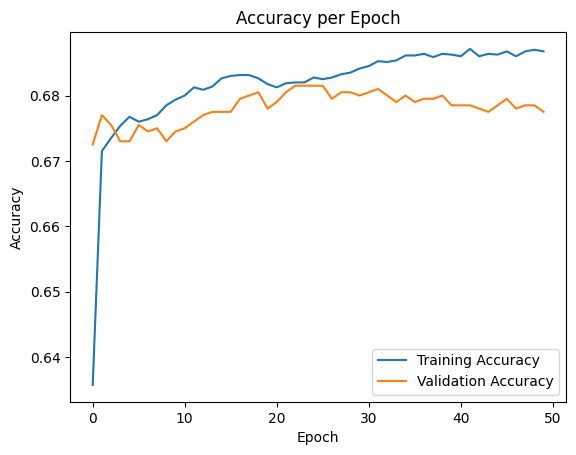

In [63]:
# Accuracy per epoch
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [66]:

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)
acc = accuracy_score(y_test, y_pred)

print("Final Accuracy: {:.2f}%".format(acc * 100))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Final Accuracy: 67.75%


In [67]:
acc = accuracy_score(y_test, y_pred)
print("Final Accuracy: {:.2f}%".format(acc * 100))


Final Accuracy: 67.75%


In [68]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[803 229   0   0]
 [348 552   0   0]
 [ 29  24   0   0]
 [  9   6   0   0]]
